# 09 · End to end: from spectra to an orbit

**What you'll learn**

- how to simulate a season of HARPS-like observations of a star with a companion
- how the pieces of notebooks 03 and 06 chain together: spectra → RVs → periodogram
- how to fit the orbit and check the period and amplitude against the truth
- why nightly sampling creates 1-day aliases

Each step is a public function on plain arrays (the simulator, `unicor`, `sparta.pdc`,
astropy's `LombScargle`, `scipy.optimize.curve_fit`); the last cell repeats the chain with the
`Observations` object and checks that the numbers agree.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle
from scipy.optimize import curve_fit

from sparta.instruments.simulated import Simulation, component_spectra, simulate
from sparta.pdc import pdc_power, pdc_pvalue, scalar_distance_matrix, unbiased_u_centering
from sparta.plotting import (EXTRA_COLOR, GREY, MODEL_COLOR, apply_style, plot_curve, plot_model,
                             plot_points)
from sparta.preprocess import coarsest_native_step, resample_to_log_grid
from unicor import ccf_order

apply_style()

## 1. The observing schedule

A typical ground-based season: 40 clear nights scattered over 120, one spectrum per night, taken
near local midnight (within about ±1.5 hours).

In [2]:
rng = np.random.default_rng(5)
nights = np.sort(rng.choice(120, size=40, replace=False))
times = nights + 0.5 + rng.normal(0, 0.06, nights.size)          # days
print(f"{times.size} epochs over {np.ptp(times):.0f} days")

40 epochs over 116 days


## 2. The star and its orbit

A Sun-like star (PHOENIX 5500 K) with an unseen companion on a circular 3.17-day orbit,
semi-amplitude 12 m/s, systemic velocity −10 km/s: a single-lined (SB1) orbit. The spectra are
simulated as the HARPS archive would deliver them (`as_product=True`: rebinned onto its 0.01 Å
grid), at signal-to-noise 50 per pixel. `simulate` returns one record per epoch, with plain
wavelength (Å, air) and flux arrays per order, and the truth.

In [3]:
P_true, K_true, gamma_true = 3.17, 0.012, -10.0                  # days, km/s, km/s
rv_true = gamma_true + K_true * np.sin(2 * np.pi * times / P_true + 0.7)

sim = Simulation(like="HARPS", components=[dict(teff=5500, logg=4.5, vsini=2.0)],
                 times=times, rv_kms=rv_true, snr=50, seed=5, as_product=True)
records, truth = simulate(sim)
waves = [rec.wave[0] for rec in records]                         # one order per epoch
fluxes = [rec.flux[0] for rec in records]
print(f"{len(records)} spectra, {waves[0][0]:.1f}-{waves[0][-1]:.1f} Å, step {np.diff(waves[0])[0]:.3f} Å")

t0 = int(times.min())                                            # only time differences matter
t = times - t0                                                   # days since day t0

40 spectra, 4990.0-5090.0 Å, step 0.010 Å


## 3. Radial velocities

UNICOR against the matched template (notebook 03): the star's rest-frame model as the simulator
built it (`component_spectra`). Each epoch is resampled onto a log-λ grid of step 0.1 km/s
(`resample_to_log_grid`, notebook 02) and cross-correlated with `ccf_order` over ±30 km/s,
which also returns the RV's maximum-likelihood uncertainty.

The uncertainty counts independent pixels, and resampling adds none. The archive rebinned the
detector's pixels (0.609 km/s for HARPS) onto 0.01 Å bins (about 0.6 km/s here); the information
is that of the coarser of the two (`coarsest_native_step`), the record's `native_step_kms`.

In [4]:
t_wave, t_flux = component_spectra(sim)[0][0]                    # rest frame, order 0
dv, n_lags = 0.1, 300                                            # km/s; ±30 km/s
natives = [coarsest_native_step(rec.native_step_kms[0], w) for rec, w in zip(records, waves)]

orders = []
for w, f, native in zip(waves, fluxes, natives):
    log_w, log_f = resample_to_log_grid(w, f, dv)
    orders.append(ccf_order(log_w, log_f, t_wave, t_flux, n_lags, dv_kms=dv,
                            native_step_kms=native, errors=True))
rv = np.array([o.rv for o in orders])                            # km/s
erv = np.array([o.erv for o in orders])
print(f"native step {natives[0]:.3f} km/s; median RV uncertainty: {np.median(erv) * 1e3:.1f} m/s;  "
      f"rms about the truth: {np.std(rv - rv_true) * 1e3:.1f} m/s;  K = {K_true * 1e3:.0f} m/s")

native step 0.609 km/s; median RV uncertainty: 3.5 m/s;  rms about the truth: 2.8 m/s;  K = 12 m/s


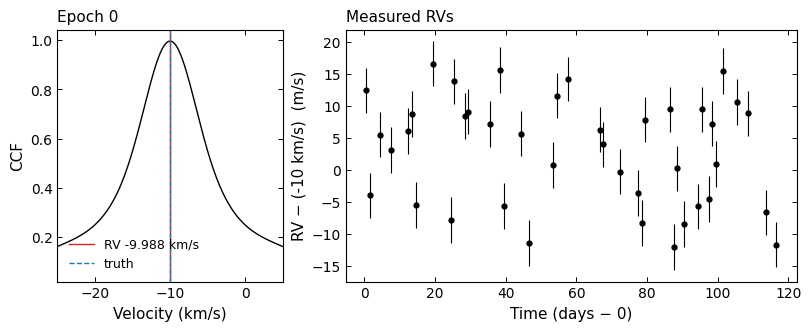

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3.2), width_ratios=[1, 2])
o = orders[0]
plot_curve(axs[0], o.velocity, o.ccf)
axs[0].axvline(o.rv, color=MODEL_COLOR, lw=1, label=f"RV {o.rv:.3f} km/s")
axs[0].axvline(rv_true[0], color=EXTRA_COLOR, ls="--", lw=1, label="truth")
axs[0].set_xlim(o.rv - 15, o.rv + 15)
axs[0].set_xlabel("Velocity (km/s)")
axs[0].set_ylabel("CCF")
axs[0].set_title("Epoch 0", loc="left")
axs[0].legend(loc="lower left")
plot_points(axs[1], t, (rv - gamma_true) * 1e3, erv * 1e3)
axs[1].set_xlabel(f"Time (days − {t0})")
axs[1].set_ylabel(f"RV − ({gamma_true:g} km/s)  (m/s)")
axs[1].set_title("Measured RVs", loc="left")
plt.show()

## 4. The periodogram

GLS and PDC on the RVs (notebook 06): `LombScargle(t, rv)` and `pdc_power` of the U-centred RV
distances. With one spectrum per night, frequencies $f$ and $1 - f$ (1/day) are hard to tell
apart: the **1-day alias**. Frequencies near 1/day itself are degenerate (every spectrum taken at
the same time of night), so the grid stops below them.

In [6]:
freqs = np.arange(0.02, 0.95, 1 / 2000)                          # 1/day
n = t.size
periodograms = {
    "GLS": LombScargle(t, rv).power(freqs),
    "PDC": pdc_power(t, freqs, unbiased_u_centering(scalar_distance_matrix(rv), n)),
}

f_alias = 1 - 1 / P_true
for name, power in periodograms.items():
    k = np.argmax(power)
    i_alias = np.argmin(np.abs(freqs - f_alias))
    print(f"{name}: peak at P = {1 / freqs[k]:.3f} d (power {power[k]:.3f}); "
          f"1-day alias P = {1 / f_alias:.3f} d has power {power[i_alias]:.3f}")
print(f"local PDC p-value of the peak: {pdc_pvalue(periodograms['PDC'].max(), n):.1e}")

GLS: peak at P = 3.170 d (power 0.894); 1-day alias P = 1.461 d has power 0.830
PDC: peak at P = 3.175 d (power 0.615); 1-day alias P = 1.461 d has power 0.571
local PDC p-value of the peak: 4.2e-07


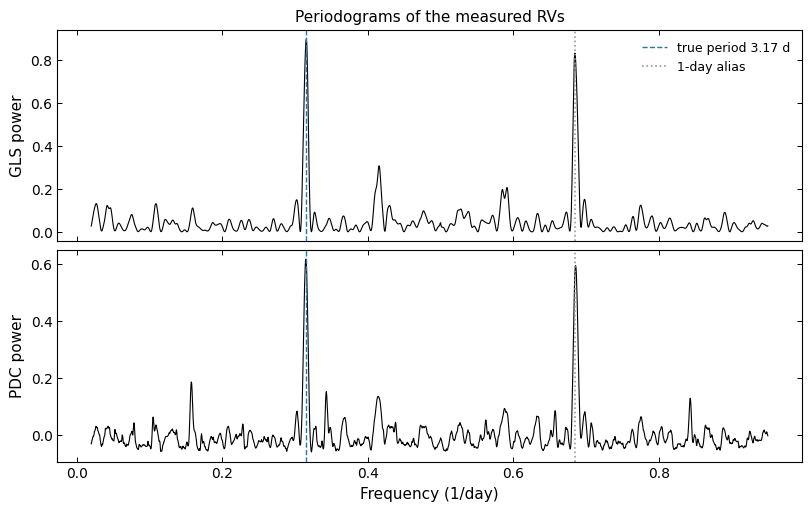

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for ax, (name, power) in zip(axs, periodograms.items()):
    plot_curve(ax, freqs, power, lw=0.8)
    ax.axvline(1 / P_true, color=EXTRA_COLOR, ls="--", lw=1, label=f"true period {P_true} d")
    ax.axvline(f_alias, color=GREY, ls=":", lw=1.2, label="1-day alias")
    ax.set_ylabel(f"{name} power")
axs[0].legend(loc="upper right")
axs[0].set_title("Periodograms of the measured RVs")
axs[1].set_xlabel("Frequency (1/day)")
plt.show()

## 5. Fit the orbit

A circular orbit is a sinusoid, $v(t) = \gamma + K \sin(2\pi t/P + \phi)$. A weighted least-squares
fit (`scipy.optimize.curve_fit`, with the RV uncertainties) started at the GLS peak gives
$P$ and $K$ with their uncertainties.

In [8]:
def circular_orbit(t, P, K, phi, gamma):
    return gamma + K * np.sin(2 * np.pi * t / P + phi)

f_best = freqs[np.argmax(periodograms["GLS"])]
start = [1 / f_best, np.std(rv) * np.sqrt(2), 0.0, np.mean(rv)]
popt, pcov = curve_fit(circular_orbit, t, rv, p0=start, sigma=erv, absolute_sigma=True)
if popt[1] < 0:                                   # K < 0 is the same orbit, half a cycle later
    popt[1], popt[2] = -popt[1], popt[2] + np.pi
P_fit, K_fit = popt[0], popt[1]
P_err, K_err = np.sqrt(pcov[0, 0]), np.sqrt(pcov[1, 1])

print(f"P = {P_fit:.4f} ± {P_err:.4f} d     (truth {P_true}; off by {(P_fit - P_true) / P_err:+.1f} σ)")
print(f"K = {K_fit * 1e3:.1f} ± {K_err * 1e3:.1f} m/s     (truth {K_true * 1e3:.0f}; off by {(K_fit - K_true) / K_err:+.1f} σ)")
chi2_red = np.sum(((rv - circular_orbit(t, *popt)) / erv) ** 2) / (t.size - 4)
print(f"reduced chi2 of the fit: {chi2_red:.2f}")
assert abs(P_fit - P_true) < 2 * P_err and abs(K_fit - K_true) < 2 * K_err

P = 3.1705 ± 0.0032 d     (truth 3.17; off by +0.2 σ)
K = 11.5 ± 0.8 m/s     (truth 12; off by -0.6 σ)
reduced chi2 of the fit: 0.65


Both within 1σ of the truth. The reduced χ² is below 1 because these spectra have *photon* noise
(the simulator's default; notebook 03 used constant noise): it is lower in the line cores, where
the RV information is, so the reported uncertainties come out somewhat conservative (compare the
rms about the truth with the median uncertainty in section 3).

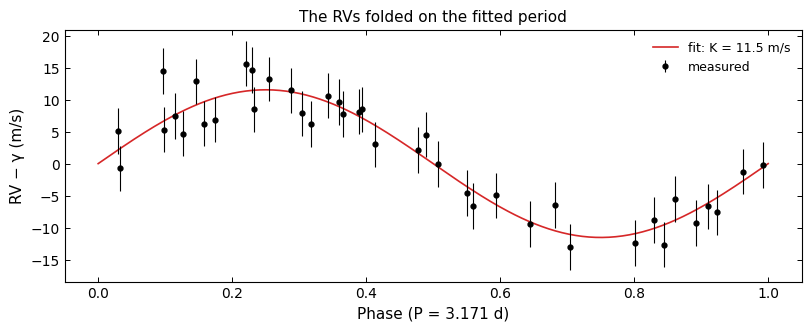

In [9]:
phase = ((t / P_fit + popt[2] / (2 * np.pi)) % 1)
grid = np.linspace(0, 1, 300)
fig, ax = plt.subplots()
plot_points(ax, phase, (rv - popt[3]) * 1e3, erv * 1e3, label="measured")
plot_model(ax, grid, K_fit * 1e3 * np.sin(2 * np.pi * grid), label=f"fit: K = {K_fit * 1e3:.1f} m/s")
ax.set_xlabel(f"Phase (P = {P_fit:.3f} d)")
ax.set_ylabel("RV − γ (m/s)")
ax.set_title("The RVs folded on the fitted period")
ax.legend(loc="upper right")
plt.show()

## The same numbers with the objects

`Observations(survey='SIMULATED', simulation=sim)` ingests the same records as archive files
(barycentric correction, which is zero here; times relative to the integer day of the first
spectrum; the archive's native step), `calc_rv_against_template` runs `ccf_order` per order, and
the `PeriodicityDetector` scans the same grid. The RVs are combined over orders by maximum
likelihood (`combine_ccfs`, notebook 03) on a lag axis computed once for all orders; with one
order that is the same CCF up to rounding, a different code path, so the RVs and the
periodograms of them are compared to $10^{-9}$ (km/s for the RVs) rather than bit for bit.
[howto/05_simulate_data](../howto/05_simulate_data.ipynb) and
[howto/01_measure_rvs](../howto/01_measure_rvs.ipynb) are the short recipes.

In [10]:
from sparta import Observations
from sparta.instruments.simulated import component_templates

obs = Observations(survey="SIMULATED", simulation=sim)
assert obs.first_time == t0 and np.array_equal(obs.time_list, t)
obs.calc_rv_against_template(component_templates(sim)[0], dv=0.1, vel_bound=30)
assert np.allclose(obs.vels, rv, rtol=0, atol=1e-9)              # km/s
assert np.allclose(obs.evels, erv, rtol=0, atol=1e-9)

obs.init_periodicity_detector(freq_range=(0.02, 0.95), periodogram_grid_resolution=2000)
pd = obs.periodicity_detector
pd.calc_gls()
pd.calc_pdc()
assert np.array_equal(pd.frequency_grid, freqs)
for key, name in (("GLS", "GLS"), ("PDC_unbiased", "PDC")):
    assert np.allclose(pd.results_power[key], periodograms[name], rtol=0, atol=1e-9)
print(f"RVs: largest difference {np.max(np.abs(obs.vels - rv)):.1e} km/s; periodograms: "
      f"{max(np.max(np.abs(pd.results_power[k] - periodograms[m])) for k, m in (('GLS', 'GLS'), ('PDC_unbiased', 'PDC'))):.1e}")

RVs: largest difference 0.0e+00 km/s; periodograms: 0.0e+00


## Summary

- `simulate(Simulation(...))` gives spectra with a known truth, as plain arrays per epoch.
- `resample_to_log_grid` → `ccf_order` → `LombScargle` / `pdc_power` take you from spectra to a
  period; a sinusoid fit gives $P$ and $K$, here consistent with the truth.
- The RV uncertainty counts the information of the coarsest sampling the data have had
  (`coarsest_native_step`), not the archive's bins.
- Nightly sampling makes 1-day aliases; check the alias peak before trusting a period.

Where to go next: notebook 07 for periodicities in the spectra themselves (USuRPER), the TODCOR
deep dives in [`howto/todcor_detailed/`](../howto/todcor_detailed/) for the mathematics of the two-template fit, and `docs/instruments.md`
for every supported instrument.